# Tournament scheduling

The Riverbend Cup is a fictional 15-day tournament. Eight teams share four courts, each court is
filled once a day, and every team has given the organizers a list of days it cannot play. The
question is **which team takes which court on which day**, so that no team plays twice in a day and
nobody can complain: every team plays about as often as the others, and every pair of teams shares a
match day about as often as any other pair.

In this notebook you will:

1. describe a tournament as Python objects,
2. solve it, and see why a perfect fairness score can still bench a team,
3. print the court grid and the fairness of each team,
4. check the result yourself, and prove it cannot be improved,
5. change the rules and see the head-to-head table fall apart,
6. let teams ask for more days off and find where the tournament stops working,
7. repair a published schedule with pinned days, and restart the search from an existing one.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

from optimaru import tournament_scheduling as ts
from optimaru.tournament_scheduling.constraints import get_constraints
from optimaru.tournament_scheduling.models import (
    DayModel, TeamAssignmentModel, TeamModel, TournamentScheduleModel, UnavailabilityPenaltyModel,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the tournament

| Object | What it holds |
| --- | --- |
| `TeamModel` | a name. Everything else refers to a team by its list position |
| `DayModel` | one match day |
| `UnavailabilityPenaltyModel` | one (team, day) pair the team cannot play |
| `TeamAssignmentModel` | one slot to fill: an id, a day, and `index_in_day`, used here as the court |

`TeamAssignmentModel.team` is the one decision. These pydantic models serialize to JSON, and `solve`
accepts them directly. Pairs of teams count as a head-to-head when both have a slot on the same day.
The model has no notion of who plays whom on a given court.

The days off are drawn with a seeded generator, so asking for more of them keeps the earlier ones.

In [2]:
TEAMS = ["Alder", "Birch", "Cedar", "Dogwood", "Elm", "Fir", "Ginkgo", "Hazel"]
DAY_COUNT, COURTS = 15, 4
TEAM_COLOR = dict(zip(TEAMS, COLORS))
DARK_TEXT = {"Birch", "Cedar", "Dogwood", "Elm"}  # teams whose fill needs ink rather than white
DAYS_OFF = 40


def days_off(count):
    rng = np.random.default_rng(3)
    drawn = []
    while len(drawn) < count:
        pair = (int(rng.integers(len(TEAMS))), int(rng.integers(DAY_COUNT)))
        if pair not in drawn:
            drawn.append(pair)
    return drawn


def make_tournament(off=DAYS_OFF):
    return TournamentScheduleModel(
        teams=[TeamModel(name=name) for name in TEAMS],
        days=[DayModel(date_index=day) for day in range(DAY_COUNT)],
        unavailability_penalties=[UnavailabilityPenaltyModel(team=t, day=d) for t, d in days_off(off)],
        team_assignments=[TeamAssignmentModel(id=day * COURTS + court, day=day, index_in_day=court)
                          for day in range(DAY_COUNT) for court in range(COURTS)],
    )


def available_per_day(problem):
    off = {(p.team, p.day) for p in problem.unavailability_penalties}
    return [sum((t, d) not in off for t in range(len(TEAMS))) for d in range(DAY_COUNT)]


problem = make_tournament()
print(f"{len(problem.teams)} teams, {len(problem.days)} days, {len(problem.team_assignments)} slots, "
      f"{len(problem.unavailability_penalties)} days off")
print("teams available per day:", available_per_day(problem))

8 teams, 15 days, 60 slots, 40 days off
teams available per day: [6, 4, 7, 5, 5, 6, 5, 5, 6, 5, 5, 4, 6, 5, 6]


Each day needs four different teams, so a day with exactly four available teams has no choice in it.
This grid is the input the solver gets. The same layout shows the solution later.

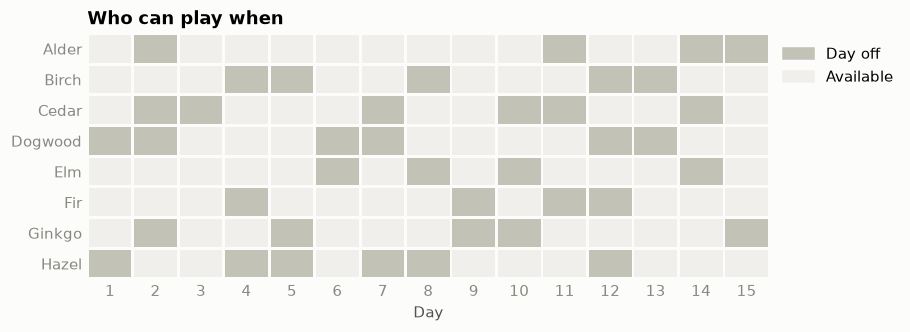

In [3]:
def team_day_grid(ax, problem, result=None):
    """Teams as rows, days as columns. Gray cells are days off. With a result, cells show the court."""
    off = {(p.team, p.day) for p in problem.unavailability_penalties}
    played = {} if result is None else {(a.team, a.day): a.index_in_day for a in result.team_assignments}
    for t, name in enumerate(TEAMS):
        for day in range(DAY_COUNT):
            fill = "#c3c2b7" if (t, day) in off else "#f0efec"
            if (t, day) in played:
                fill = TEAM_COLOR[name]
            ax.fill_between([day + 0.03, day + 0.97], t + 0.05, t + 0.95, color=fill, linewidth=0)
            if (t, day) in played:
                ax.text(day + 0.5, t + 0.5, played[t, day] + 1, ha="center", va="center", fontsize=8,
                        color="#0b0b0b" if name in DARK_TEXT else "white")
    ax.set_xlim(0, DAY_COUNT)
    ax.set_ylim(len(TEAMS), 0)
    ax.set_xticks(np.arange(DAY_COUNT) + 0.5, np.arange(DAY_COUNT) + 1)
    ax.set_yticks(np.arange(len(TEAMS)) + 0.5, TEAMS)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_xlabel("Day")


fig, ax = plt.subplots(figsize=(8, 2.9))
team_day_grid(ax, problem)
ax.set_title("Who can play when")
ax.legend(handles=[Patch(color="#c3c2b7", label="Day off"), Patch(color="#f0efec", label="Available")],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 2. Solve it

Given a pydantic model, `ts.solve` returns a new solved model and leaves the input alone. The engine
score has two numbers, and the second folds two levels into one:

- **`score_hard`**: minus the violations, where `0` means feasible. A team may hold one slot per day and
  may not play on a day off.
- **`score_soft`**: `-(medium * MEDIUM_SCALE + soft)`, with `MEDIUM_SCALE` at one million so that medium
  always wins. **Medium** is the imbalance in matches per team, **soft** the imbalance in head-to-heads
  per pair. Both use `sqrt(sum(load^2) - sum(load)^2 / n)`, and `ts.unfairness` computes it.

`0` would mean both are perfectly balanced. Look closely at what the default solve does, though.

In [4]:
TIME_LIMIT = 1
SEED = 1


def matches_per_team(result):
    counts = Counter(a.team for a in result.team_assignments)
    return [counts[t] for t in range(len(TEAMS))]


default_result = ts.solve(problem, time_limit_seconds=TIME_LIMIT, random_seed=SEED)
print("score  :", default_result.score_hard, "/", default_result.score_soft)
print("matches:", dict(zip(TEAMS, matches_per_team(default_result))))

score  : 0 / -1309313.77964
matches: {'Alder': 9, 'Birch': 9, 'Cedar': 8, 'Dogwood': 0, 'Elm': 9, 'Fir': 9, 'Ginkgo': 8, 'Hazel': 8}


Check `matches` before you trust that score. `n` in the formula counts **only teams with at least one
match**, so a team that never plays leaves the balance altogether. The default search includes macro
moves that empty a team on purpose, and it uses them when that lowers the imbalance. When the slots
divide evenly among fewer teams, the score even reaches `0`.

The rules say nothing against a benched team, and a tournament almost certainly does. Turning off
`team_count_moves` removes the only moves that cross that barrier. This is a search option and not a
rule, so keep checking `matches` on your own instances.

score  : 0 / -1414212.17124
matches: {'Alder': 8, 'Birch': 7, 'Cedar': 8, 'Dogwood': 7, 'Elm': 8, 'Fir': 7, 'Ginkgo': 8, 'Hazel': 7}


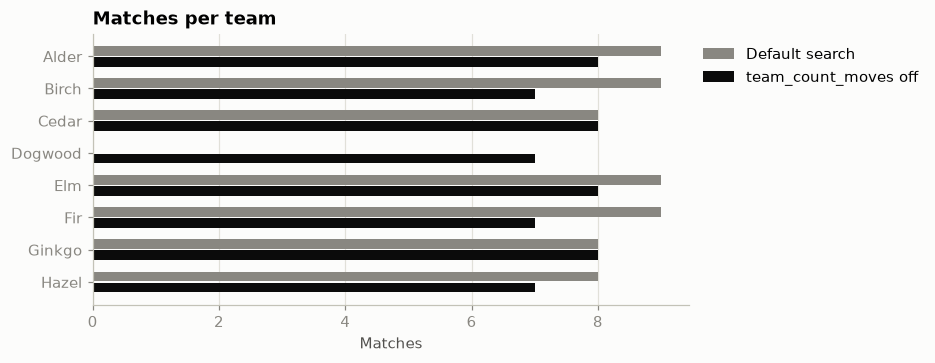

In [5]:
def make_config(steps=0):
    """A new config per solve, because solve writes its arguments into the one it is given."""
    config = ts.SolverConfig()
    config.team_count_moves = False
    config.step_count_limit = steps
    return config


result = ts.solve(problem, time_limit_seconds=TIME_LIMIT, random_seed=SEED, config=make_config())
print("score  :", result.score_hard, "/", result.score_soft)
print("matches:", dict(zip(TEAMS, matches_per_team(result))))

y = np.arange(len(TEAMS))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(y - 0.17, matches_per_team(default_result), height=0.3, color=MUTED, label="Default search")
ax.barh(y + 0.17, matches_per_team(result), height=0.3, color="#0b0b0b", label="team_count_moves off")
ax.set_yticks(y, TEAMS)
ax.invert_yaxis()
ax.set(title="Matches per team", xlabel="Matches")
ax.grid(True, axis="x")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### The court grid

This is the sheet that goes on the clubhouse wall: one row per court, one column per day, the same color
for a team throughout. Everything below uses the `team_count_moves` off result.

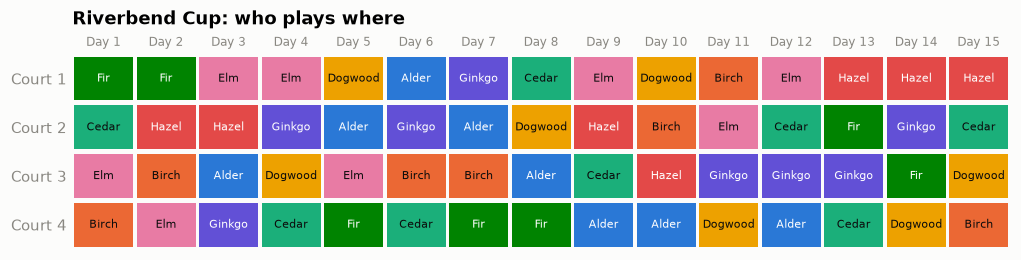

In [6]:
def court_grid(result):
    fig, ax = plt.subplots(figsize=(11, 2.3))
    for a in result.team_assignments:
        name = TEAMS[a.team]
        ax.fill_between([a.day + 0.03, a.day + 0.97], a.index_in_day + 0.05, a.index_in_day + 0.95,
                        color=TEAM_COLOR[name], linewidth=0)
        ax.text(a.day + 0.5, a.index_in_day + 0.5, name, ha="center", va="center", fontsize=7.5,
                color="#0b0b0b" if name in DARK_TEXT else "white")
    ax.set_xlim(0, DAY_COUNT)
    ax.set_ylim(COURTS, 0)
    ax.set_xticks(np.arange(DAY_COUNT) + 0.5, [f"Day {d + 1}" for d in range(DAY_COUNT)], fontsize=8)
    ax.set_yticks(np.arange(COURTS) + 0.5, [f"Court {c + 1}" for c in range(COURTS)])
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_title("Riverbend Cup: who plays where", pad=8)
    plt.show()


court_grid(result)

The same schedule per team. The number in each cell is the court, and gray cells are days off.
`index_in_day` has no meaning for the score, so courts are not balanced between teams.

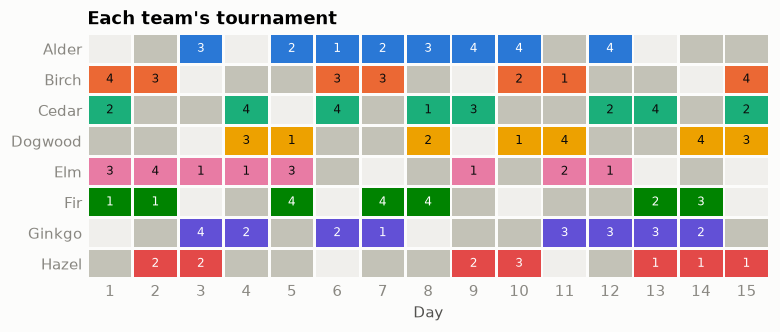

In [7]:
fig, ax = plt.subplots(figsize=(8, 2.9))
team_day_grid(ax, problem, result)
ax.set_title("Each team's tournament")
plt.show()

### Fairness per team

Two tables answer the question a team captain will ask: how many matches did we get, and how often did
we share a day with each opponent?

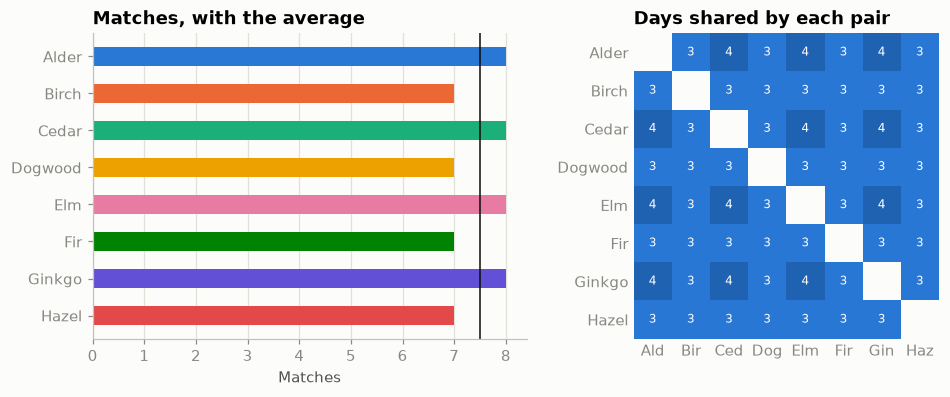

In [8]:
def head_to_head(result):
    """Symmetric matrix: days on which two teams both have a slot."""
    table = np.zeros((len(TEAMS), len(TEAMS)), dtype=int)
    by_day = {}
    for a in result.team_assignments:
        by_day.setdefault(a.day, []).append(a.team)
    for teams in by_day.values():
        for first, second in combinations(sorted(set(teams)), 2):
            table[first, second] += 1
            table[second, first] += 1
    return table


def draw_head_to_head(ax, table, title):
    ramp = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
    shown = np.ma.masked_where(np.eye(len(TEAMS), dtype=bool), table)
    ax.imshow(shown, cmap=ramp, vmin=0, vmax=6)
    for (row, col), value in np.ndenumerate(table):
        if row != col:
            ax.text(col, row, value, ha="center", va="center", fontsize=8,
                    color="white" if value >= 3 else "#0b0b0b")
    ax.set_xticks(range(len(TEAMS)), [name[:3] for name in TEAMS])
    ax.set_yticks(range(len(TEAMS)), TEAMS)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5), layout="constrained", width_ratios=[1, 1.15])
matches = matches_per_team(result)
axes[0].barh(TEAMS, matches, height=0.5, color=[TEAM_COLOR[name] for name in TEAMS])
axes[0].axvline(len(result.team_assignments) / len(TEAMS), color="#0b0b0b", linewidth=1)
axes[0].invert_yaxis()
axes[0].set(title="Matches, with the average", xlabel="Matches")
axes[0].grid(True, axis="x")
draw_head_to_head(axes[1], head_to_head(result), "Days shared by each pair")
plt.show()

## 3. Check the result yourself

All the rules can be recomputed from the assignments. The fairness terms are recomputed too, and the
score rebuilt from them, using `ts.unfairness` only for the formula.

This use case also lets you do better than "best found". With every team playing and every pair sharing a
day, both imbalances are smallest when loads differ by at most one, which gives a floor that follows from
the counts alone. The condition matters: like a benched team, a pair that never meets drops out of the
balance, so a schedule that leaves pairs apart could score lower. If the result reaches both floors, no
schedule where all teams play and all pairs meet can beat it.

In [9]:
def rebuild_score(result):
    loads = [n for n in matches_per_team(result) if n > 0]
    table = head_to_head(result)
    pairs = [int(n) for n in table[np.triu_indices(len(TEAMS), 1)] if n > 0]
    return ts.unfairness(loads), ts.unfairness(pairs)


def spread_evenly(total, parts):
    base, extra = divmod(total, parts)
    return [base + 1] * extra + [base] * (parts - extra)


per_day = Counter((a.team, a.day) for a in result.team_assignments)
off = {(p.team, p.day) for p in problem.unavailability_penalties}
print("slots left empty     :", sum(a.team is None for a in result.team_assignments))
print("two slots on one day :", sum(count > 1 for count in per_day.values()))
print("played on a day off  :", sum(pair in off for pair in per_day))

medium, soft = rebuild_score(result)
print(f"\nrebuilt score {-(medium * ts.MEDIUM_SCALE + soft):.3f}, solver {result.score_soft:.3f}")

pair_count = len(TEAMS) * (len(TEAMS) - 1) // 2
floor_medium = ts.unfairness(spread_evenly(len(result.team_assignments), len(TEAMS)))
floor_soft = ts.unfairness(spread_evenly(DAY_COUNT * COURTS * (COURTS - 1) // 2, pair_count))
print(f"medium {medium} (floor {floor_medium}), soft {soft} (floor {floor_soft})")
print("every team plays and every pair meets:", min(matches_per_team(result)) > 0
      and head_to_head(result)[np.triu_indices(len(TEAMS), 1)].min() > 0)
print("reaches both floors:", medium <= floor_medium and soft <= floor_soft)

slots left empty     : 0
two slots on one day : 0
played on a day off  : 0

rebuilt score -1414212.171, solver -1414212.171
medium 1.41421 (floor 1.41421), soft 2.17124 (floor 2.17124)
every team plays and every pair meets: True
reaches both floors: True


That explains a result that would otherwise look suspicious: different seeds tend to land on the same
score here. When they all sit on the floor, more time has nothing left to find.

## 4. Change the rules

`list_constraints()` names the four rules, and `solve(constraints=...)` scores only what you pass. `weight`
scales a rule and `exponent=2` makes large imbalances costlier. Leave the `hard` argument alone for the
medium rule, because `hard=False` folds it into soft and medium stops outranking soft.

Suppose you drop `evenly_confrontation_count`. Nobody is asked to balance head-to-heads any more, so
nothing but chance keeps teams meeting each other evenly.

['one_assignment_per_date_per_team', 'unavailability_penalty', 'fair_assignment_count_per_team', 'evenly_confrontation_count']


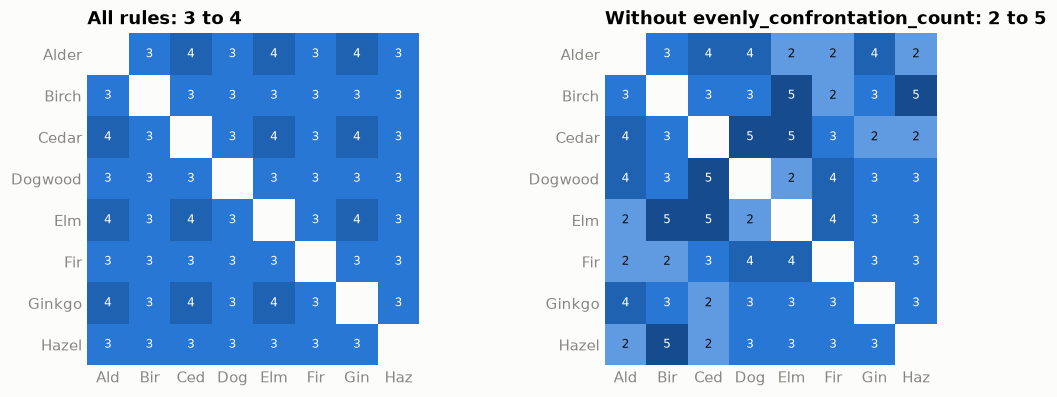

all rules    hard 0, matches [8, 7, 8, 7, 8, 7, 8, 7], shared days 3 to 4
rule dropped hard 0, matches [7, 8, 8, 8, 8, 7, 7, 7], shared days 2 to 5


In [10]:
print(ts.list_constraints())

without = [c for c in get_constraints() if c.name != "evenly_confrontation_count"]
relaxed = ts.solve(problem, time_limit_seconds=TIME_LIMIT, random_seed=SEED, config=make_config(),
                   constraints=without)

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5), layout="constrained")
for ax, run, title in [(axes[0], result, "All rules"), (axes[1], relaxed, "Without evenly_confrontation_count")]:
    pairs = head_to_head(run)[np.triu_indices(len(TEAMS), 1)]
    draw_head_to_head(ax, head_to_head(run), f"{title}: {pairs.min()} to {pairs.max()}")
plt.show()

for label, run in [("all rules", result), ("rule dropped", relaxed)]:
    pairs = head_to_head(run)[np.triu_indices(len(TEAMS), 1)]
    print(f"{label:13s}hard {run.score_hard}, matches {matches_per_team(run)}, "
          f"shared days {pairs.min()} to {pairs.max()}")

## 5. More days off

Every day needs four available teams, so a day with fewer leaves slots that can only be filled by breaking
a rule. Adding up that shortfall over the days gives the fewest hard violations any schedule can have.
Below, teams ask for more and more days off, and each dot is one run.

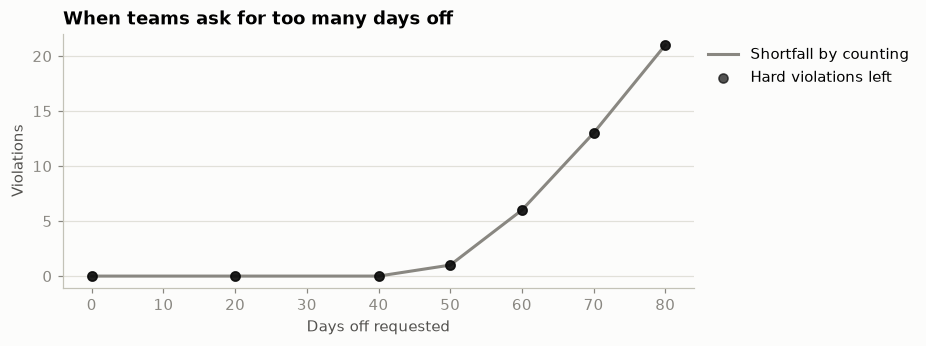

 0 days off: shortfall  0, hard violations left 0
 0 days off: shortfall  0, hard violations left 0
20 days off: shortfall  0, hard violations left 0
20 days off: shortfall  0, hard violations left 0
40 days off: shortfall  0, hard violations left 0
40 days off: shortfall  0, hard violations left 0
50 days off: shortfall  1, hard violations left 1
50 days off: shortfall  1, hard violations left 1
60 days off: shortfall  6, hard violations left 6
60 days off: shortfall  6, hard violations left 6
70 days off: shortfall 13, hard violations left 13
70 days off: shortfall 13, hard violations left 13
80 days off: shortfall 21, hard violations left 21
80 days off: shortfall 21, hard violations left 21


In [11]:
def shortfall(problem):
    return sum(max(0, COURTS - available) for available in available_per_day(problem))


requests = [0, 20, 40, 50, 60, 70, 80]
sweep = []
for count in requests:
    case = make_tournament(count)
    for seed in (1, 2):
        run = ts.solve(case, time_limit_seconds=0.4, random_seed=seed, config=make_config())
        sweep.append((count, shortfall(case), -run.score_hard))

fig, ax = plt.subplots(figsize=(7.4, 3))
ax.plot(requests, [shortfall(make_tournament(count)) for count in requests], color=MUTED, linewidth=2,
        label="Shortfall by counting")
ax.scatter([count for count, *_ in sweep], [hard for *_, hard in sweep], s=36, color="#0b0b0b", alpha=0.7,
           zorder=2, label="Hard violations left")
ax.set(title="When teams ask for too many days off", xlabel="Days off requested", ylabel="Violations")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

for count, gap, hard in sweep:
    print(f"{count:2d} days off: shortfall {gap:2d}, hard violations left {hard}")

Any dot on the gray line matches a bound no schedule can beat, so the tournament needs fewer requests or
more teams, not more search. A dot above the line would mean a better schedule may still exist.

## 6. Repair a published schedule

After eight days, one team reports that it cannot play three of its remaining match days. The days already
played cannot change, so they are pinned: set `team` and `pinned=True` on the problem, and the search keeps
them. `with_initial_solution(problem, solution)` starts from the published schedule, and pinned slots keep
their team whatever the solution says. A time limit of `0` shows the published schedule against the news.

Hazel cannot play days [9, 10, 13]
published schedule against the news: -3 / -1414212.17124


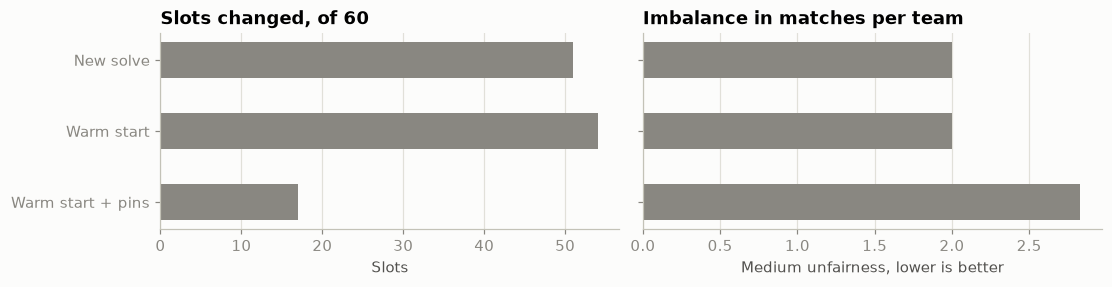

New solve         hard 0, matches [7, 8, 7, 8, 8, 8, 8, 6], changed 51
Warm start        hard 0, matches [7, 8, 8, 7, 8, 8, 8, 6], changed 54
Warm start + pins hard 0, matches [8, 8, 7, 8, 8, 8, 8, 5], changed 17


In [12]:
PLAYED_DAYS = 8
available = available_per_day(problem)
late_days = [day for day in range(PLAYED_DAYS, DAY_COUNT) if available[day] > COURTS]  # days that can lose a team


def late_matches(team):
    return [a.day for a in result.team_assignments if a.team == team and a.day in late_days]


injured = max(range(len(TEAMS)), key=lambda team: len(late_matches(team)))
lost_days = late_matches(injured)[:3]


def changed_problem():
    model = make_tournament()
    model.unavailability_penalties += [UnavailabilityPenaltyModel(team=injured, day=day) for day in lost_days]
    return model


def pinned_problem():
    model = changed_problem()
    for slot, old in zip(model.team_assignments, result.team_assignments):
        if slot.day < PLAYED_DAYS:
            slot.team, slot.pinned = old.team, True
    return model


def slots_changed(run):
    return sum(a.team != b.team for a, b in zip(run.team_assignments, result.team_assignments))


news = ts.solve(ts.with_initial_solution(changed_problem(), result), time_limit_seconds=0, config=make_config())
print(f"{TEAMS[injured]} cannot play days {[day + 1 for day in lost_days]}")
print("published schedule against the news:", news.score_hard, "/", news.score_soft)

repairs = {
    "New solve": ts.solve(changed_problem(), time_limit_seconds=TIME_LIMIT, random_seed=3, config=make_config()),
    "Warm start": ts.solve(ts.with_initial_solution(changed_problem(), result), time_limit_seconds=TIME_LIMIT,
                           random_seed=3, config=make_config()),
    "Warm start + pins": ts.solve(ts.with_initial_solution(pinned_problem(), result),
                                  time_limit_seconds=TIME_LIMIT, random_seed=3, config=make_config()),
}
names = list(repairs)
fig, axes = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True, layout="constrained")
axes[0].barh(names, [slots_changed(run) for run in repairs.values()], height=0.5, color=MUTED)
axes[0].set(title=f"Slots changed, of {len(result.team_assignments)}", xlabel="Slots")
axes[1].barh(names, [rebuild_score(run)[0] for run in repairs.values()], height=0.5, color=MUTED)
axes[1].set(title="Imbalance in matches per team", xlabel="Medium unfairness, lower is better")
axes[0].invert_yaxis()
for ax in axes:
    ax.grid(True, axis="x")
plt.show()

for name, run in repairs.items():
    print(f"{name:18s}hard {run.score_hard}, matches {matches_per_team(run)}, changed {slots_changed(run)}")

With the played days pinned, the teams can only even things out over the days that remain, so a stable
schedule and a fair one pull against each other. Pinning the played days is not optional in a real
tournament. The chart shows what that fact costs.

### Keep improving a schedule

Restarts continue from a schedule you already have. **Give each restart its own `random_seed`.** The same
start with the same seed repeats the same search. A same-seed round can still improve while its start
differs from the round before, but once a round finds nothing, it hands back its own start and every
later round is the same search again.

Normal solves on this instance reach the floor at once, which leaves restarts nothing to do. So these
rounds start from the construction heuristic (a time limit of `0`) and get a step limit of 1000. Steps do
not depend on the machine's speed, so this chart does not change with the clock. The chart measures
the gap to the floor.

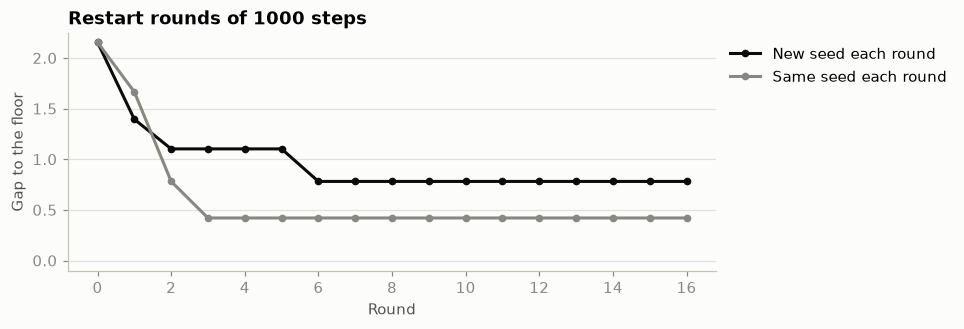

new seed : [2.15, 1.39, 1.1, 1.1, 1.1, 1.1, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78, 0.78]
same seed: [2.15, 1.66, 0.78, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42, 0.42]
slots moved by one more same-seed round: 0
gap after one more restart of 1 s instead of 1000 steps: 0.00


In [13]:
FLOOR = floor_medium * ts.MEDIUM_SCALE + floor_soft
start = ts.solve(problem, time_limit_seconds=0, config=make_config())


def restart_rounds(seeds):
    current, history = start, [-start.score_soft - FLOOR]
    for seed in seeds:
        seeded = ts.with_initial_solution(problem, current)
        current = ts.solve(seeded, time_limit_seconds=5, random_seed=seed, config=make_config(steps=1000))
        history.append(-current.score_soft - FLOOR)
    return current, history


last_new, new_seeds = restart_rounds(range(2, 18))
settled, same_seed = restart_rounds([SEED] * 16)

fig, ax = plt.subplots(figsize=(7.6, 2.8))
ax.plot(new_seeds, color="#0b0b0b", linewidth=2, marker="o", markersize=4, label="New seed each round")
ax.plot(same_seed, color=MUTED, linewidth=2, marker="o", markersize=4, label="Same seed each round")
ax.set(title="Restart rounds of 1000 steps", xlabel="Round", ylabel="Gap to the floor")
ax.set_ylim(-0.1, None)
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

repeat = ts.solve(ts.with_initial_solution(problem, settled), time_limit_seconds=5, random_seed=SEED,
                  config=make_config(steps=1000))
print("new seed :", [round(gap, 2) for gap in new_seeds])
print("same seed:", [round(gap, 2) for gap in same_seed])
print("slots moved by one more same-seed round:",
      sum(a.team != b.team for a, b in zip(repeat.team_assignments, settled.team_assignments)))

longer = ts.solve(ts.with_initial_solution(problem, last_new), time_limit_seconds=TIME_LIMIT, random_seed=18,
                  config=make_config())
print(f"gap after one more restart of {TIME_LIMIT} s instead of 1000 steps: {-longer.score_soft - FLOOR:.2f}")

A flat stretch on the black line means that seed found nothing in its steps, and the best schedule so far is
kept. Which line sits lower at any point depends on the seeds, so read the chart for the shape: the gray
line cannot leave a flat stretch, and the black one can. A round of 1000 steps is also a small budget. The
last line of the output shows what one restart gets with a normal time limit.

## Next steps

- `solve` also takes `parallel_solver_count`, and `ts.constraint_costs` returns the raw cost of each rule.
- `use-cases/tournament-scheduling/README.md` covers solver options and how to add moves and constraints in
  C++.
- For a season of home and away fixtures with travel, see `sports-league-scheduling.ipynb`.